**Housing Prices Dataset**  
by: M YASSER H  
source: Kaggle  
link: https://www.kaggle.com/datasets/yasserh/housing-prices-dataset


**Notebook: Multiple linear regression (MLR)**  
by: Kent Justin Canja REE, PSM, PSPO, SO2

In [53]:
# Libraries and Packages
import kagglehub
from kagglehub import KaggleDatasetAdapter
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np 

In [17]:
# Pull Data in Kaggle via Code Execution
file_path = "Housing.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "yasserh/housing-prices-dataset",
    file_path,
)

print(f"Data Head:\n{df.head()}")

Data Head:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


# Exploratory Data Analysis

In [18]:
housing_df = df.copy()

print(f"Data Information:\n{housing_df.info()}\n")
print(f"Data Description:\n{housing_df.describe()}\n")



<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB
Data Information:
None

Data Description:
              price          area    bedrooms   bathrooms     stories  \
count  5.450000e+02    545.000000  545.000000  545.000000  545.000000

In [21]:
# Check for Null / Missing Values
print(f"Missing Values:\n{housing_df.isnull().sum()}\n")

# Check for Duplicates
print(f"Duplicates:\n{housing_df.duplicated().sum()}")

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicates:
0


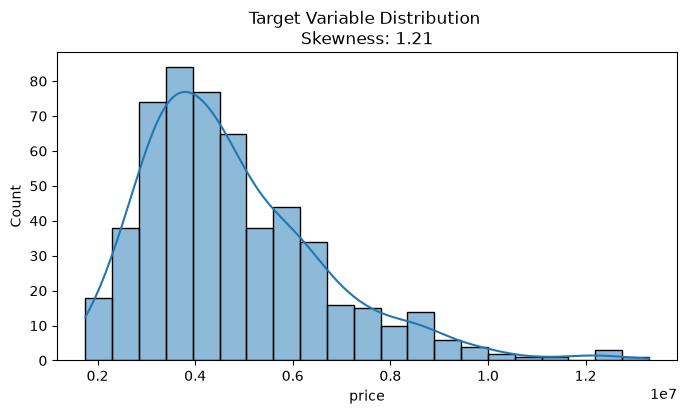

In [31]:
# Visualizing Target Variable "Price"
plt.figure(figsize=(8, 4))
sns.histplot(housing_df['price'], kde=True)
plt.title(f"Target Variable Distribution \nSkewness: {housing_df['price'].skew():.2f}")
plt.show()

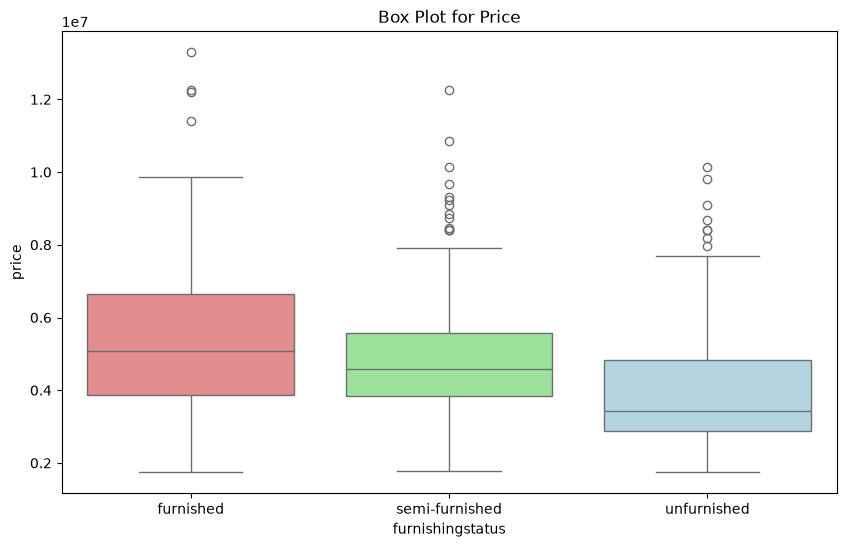

In [52]:
# Box Plot
plt.figure(figsize=(10, 6))
palette = {'unfurnished': 'lightblue', 'semi-furnished': 'lightgreen', 'furnished': 'lightcoral'}
sns.boxplot(x=housing_df['furnishingstatus'], y=housing_df['price'], hue=housing_df['furnishingstatus'], data=housing_df, palette=palette)
plt.title("Box Plot for Price")
plt.show()

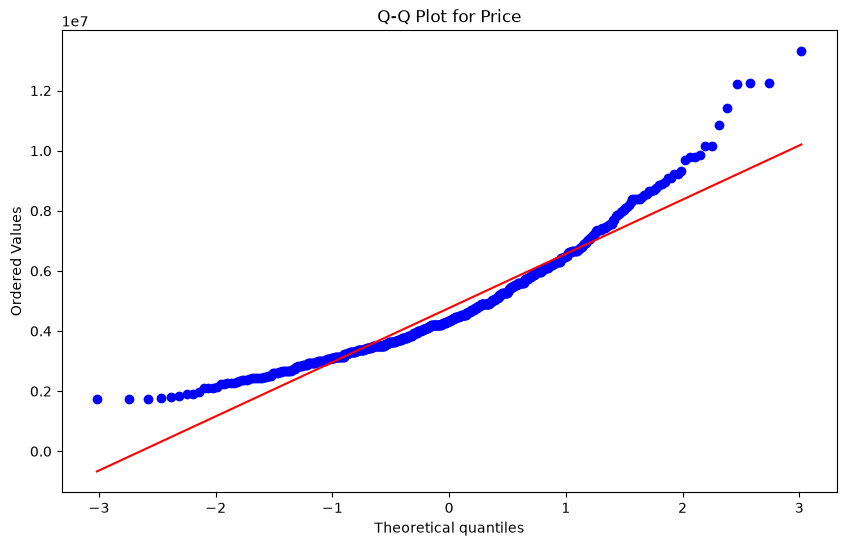

In [36]:
# Q-Q Plot
plt.figure(figsize=(10, 6))
stats.probplot(housing_df['price'], dist='norm', plot=plt)
plt.title("Q-Q Plot for Price")
plt.show()


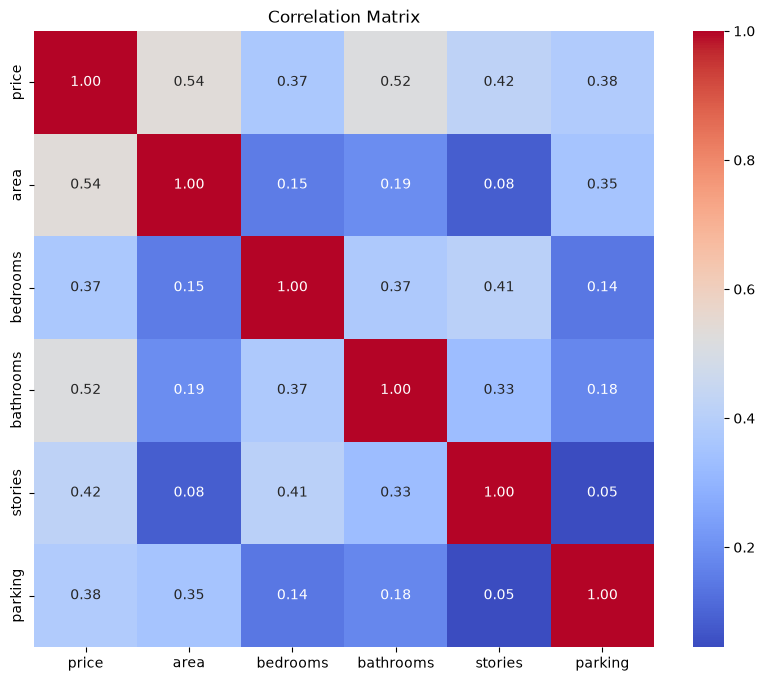

In [14]:
# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(housing_df.select_dtypes(include=['int64']).corr(), annot = True, cmap = 'coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [65]:
# Data Transformation: Log Transformation for Price
housing_df['price_log'] = np.log(housing_df['price'])
print("Original Prices")
print(housing_df['price'].head())
print("\nLog Transformed Prices")
print(housing_df['price_log'].head())

Original Prices
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64

Log Transformed Prices
0    16.403275
1    16.321036
2    16.321036
3    16.318175
4    16.250001
Name: price_log, dtype: float64


Text(0, 0.5, 'Frequency')

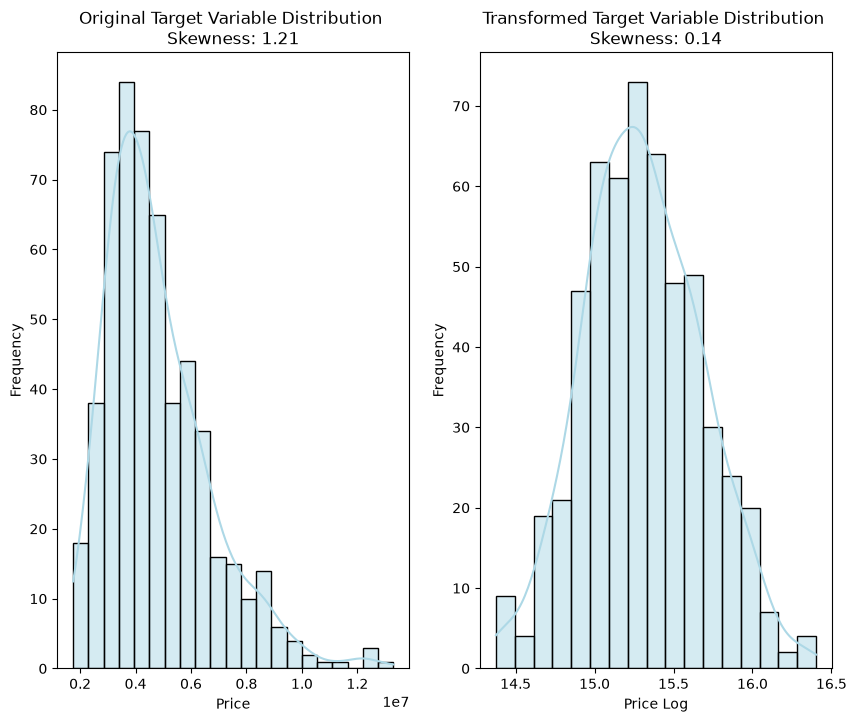

In [62]:
# Transformed Target Variabl Distribution ( Price Log )
# Original vs Transformed Target Variable Distribution ( Price Log )
plt.figure(figsize =(10, 8))
plt.subplot(1, 2, 1)
sns.histplot(housing_df['price'], kde=True, color='lightblue')
plt.title(f"Original Target Variable Distribution \nSkewness: {housing_df['price'].skew():.2f}")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
sns.histplot(housing_df['price_log'], kde=True, color='lightblue')
plt.title(f"Transformed Target Variable Distribution \nSkewness: {housing_df['price_log'].skew():.2f}")
plt.xlabel("Price Log")
plt.ylabel("Frequency")


<Axes: title={'center': 'Transformed Target Variable Distribution'}, xlabel='price_log'>

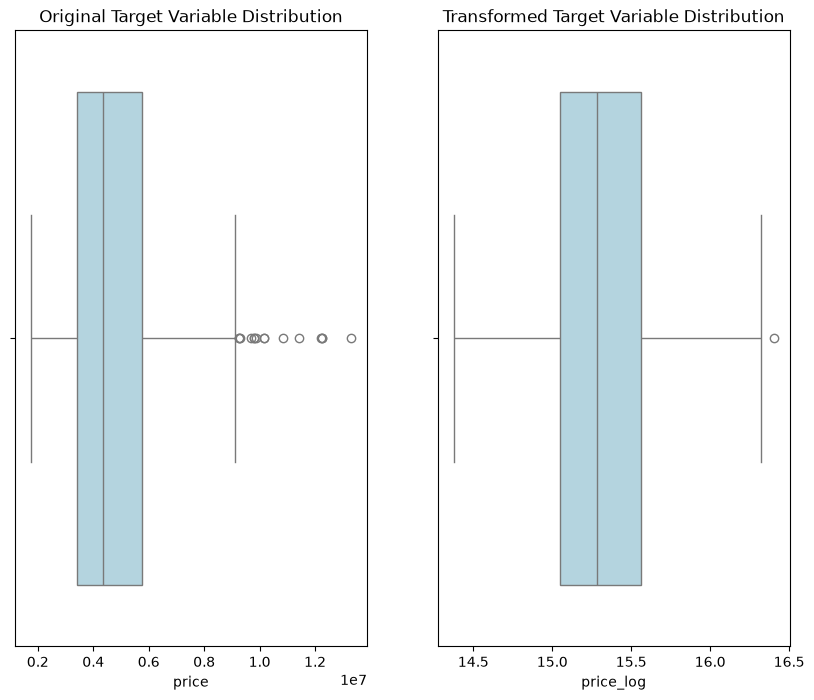

In [64]:
# Box Plot for Target Variabl
# Original vs Transformed Target Variable Distribution ( Price Log )

plt.figure(figsize=(10, 8))
plt.subplot(1, 2 ,1)
plt.title("Original Target Variable Distribution")
sns.boxplot(x=housing_df['price'], color='lightblue')

plt.subplot(1, 2, 2)
plt.title("Transformed Target Variable Distribution")
sns.boxplot(x=housing_df['price_log'], color='lightblue')

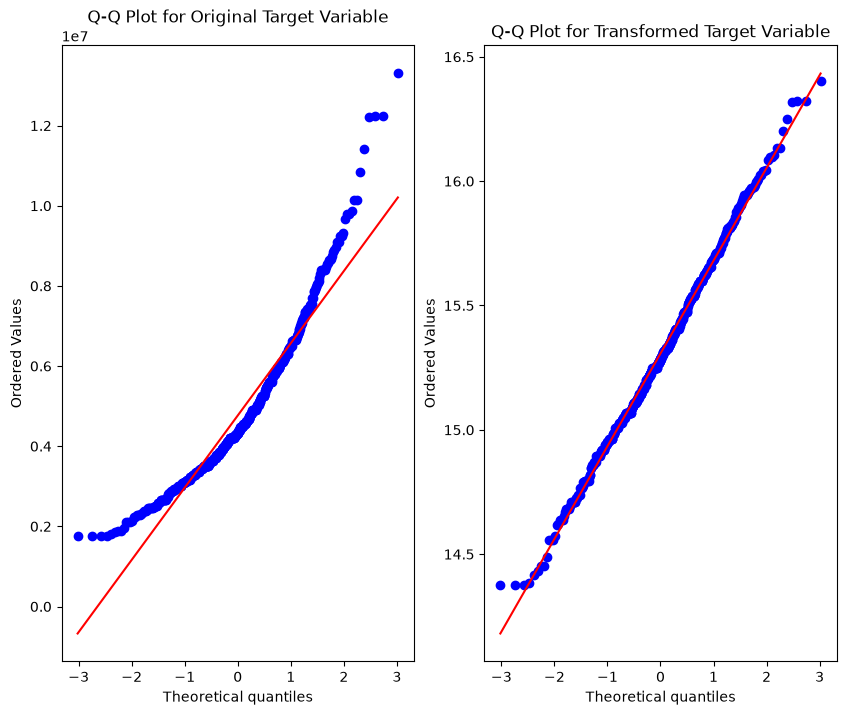

In [66]:
# Q-Q Plot for Target Variable
# Original vs Transformed Target Variable Distribution ( Price Log )
plt.figure(figsize=(10, 8))
plt.subplot(1, 2, 1)
stats.probplot(housing_df['price'], dist='norm', plot=plt)
plt.title("Q-Q Plot for Original Target Variable")

plt.subplot(1, 2, 2)
stats.probplot(housing_df['price_log'], dist='norm', plot=plt)
plt.title("Q-Q Plot for Transformed Target Variable")

plt.show()

## **Pre - Modelling EDA Findings**